In [1]:
import os
import numpy as np
import pandas as pd
from pygam import LogisticGAM, s, f, te
import matplotlib.pyplot as plt
import seaborn as sns

os.getcwd()

'/home/bee/code/mutrate'

In [2]:
# Import the scripts
from scr.landscapes import sig_per_region

In [3]:
# Load the input data
selected_sbs = ["SBS1", "SBS8", "SBS7a", "SBS9", "SBS17b", "SBS18", "SBS5", "SBS19"]

### Filter B memory cells

In [17]:
vcf_path = "data/landscapes/SNV_BMemoryDF_with_sub_and_coords.vcf"
metadata_path = "data/landscapes/colonyinfo_AX001_KX001_KX002_KX003_TX001_TX002_CB001.txt"

vcf = pd.read_csv(vcf_path, index_col=0)
metadata = pd.read_csv(metadata_path, sep="\t", index_col=0)
metadata

,meandp,Donor,CellType,Cell.type2,Tissue,Age,Project,Nmut,Nmut_adj_as,Nmut_indel,Nmut_adj_as_indel,Nmut_hsc_as,Nmut_hsc_as_indel
colony,,,,,,,,,,,,,
BMH1_plate_20181119_A01,25.874351,AX001,HSC,HSC,blood,63,1321,1108,1172.857954,40,46.740400,1111.451769,43.579816
BMH1_plate_20181119_A02,15.408956,AX001,HSC,HSC,blood,63,1321,992,1392.504593,28,58.356953,1050.870072,47.220533
BMH1_plate_20181119_A03,22.901859,AX001,HSC,HSC,blood,63,1321,1146,1275.712352,42,54.399540,1154.922795,48.901977
BMH1_plate_20181119_A04,24.805026,AX001,HSC,HSC,blood,63,1321,1058,1144.149629,41,49.692901,1063.011622,45.694143
BMH1_plate_20181119_A05,17.181319,AX001,HSC,HSC,blood,63,1321,922,1240.469182,33,58.569360,960.630084,48.682684
...,...,...,...,...,...,...,...,...,...,...,...,...,...
PD42775b_lo0018,20.822425,TX002,CD4 Naive,Naive T,tonsil,4,1903,261,255.267652,10,9.545285,255.267652,9.545285
PD42775b_lo0019,10.824350,TX002,CD8 Naive,Naive T,tonsil,4,1903,134,251.776741,6,12.152730,251.776741,12.152730
PD42775b_lo0005,8.558130,TX002,B Memory,Memory B,tonsil,4,1903,244,415.112261,4,12.028395,415.112261,12.028395


In [18]:
vcf_b = sig_per_region.vcf_preselect(vcf, metadata, ["B Memory"], save_to_csv=False)
vcf_b

,chr,pos,ref,mut,HQ.alt.freq,sample,donor,tri,call_reg,kb_id,mb_id,tri_modified
ID,,,,,,,,,,,,
1:19313907_C/T,1,19313907.0,C,T,0.454545,PD40667sc,KX002,TCG>T,20,chr1:19310001,chr1:19000001,T[C>T]G
1:25895420_G/A,1,25895420.0,G,A,0.500000,PD40667sc,KX002,GCC>T,26,chr1:25890001,chr1:25000001,G[C>T]C
1:26695199_T/C,1,26695199.0,T,C,0.700000,PD40667sc,KX002,CTC>C,27,chr1:26690001,chr1:26000001,C[T>C]C
1:27593219_G/A,1,27593219.0,G,A,0.625000,PD40667sc,KX002,TCA>T,28,chr1:27590001,chr1:27000001,T[C>T]A
1:28834029_C/T,1,28834029.0,C,T,0.444444,PD40667sc,KX002,GCT>T,29,chr1:28830001,chr1:28000001,G[C>T]T
...,...,...,...,...,...,...,...,...,...,...,...,...
X:154992059_A/G,X,154992059.0,A,G,0.500000,BMH1_PlateB4_E8,AX001,CTC>C,3052,chrX:154990001,chrX:154000001,C[T>C]C
Y:5980400_G/A,Y,5980400.0,G,A,1.000000,BMH1_PlateB4_E8,AX001,TCC>T,3059,chrY:5980001,chrY:5000001,T[C>T]C
Y:15932008_G/A,Y,15932008.0,G,A,1.000000,BMH1_PlateB4_E8,AX001,CCG>T,3069,chrY:15930001,chrY:15000001,C[C>T]G


### Building Initial Signature Matrix

In [10]:
cosmic_path = "data/landscapes/signatures/COSMIC_v3_SBS_GRCh37.txt"

sbs_blood = pd.read_csv("data/landscapes/signatures/sigfit_cosmic3_bloodsig_Aug2020.txt", 
                        sep="\t", index_col=0)
sbs_blood.rename(columns={"Signature.Blood": "SBSblood"}, inplace=True)

/tmp/ipykernel_63772/1268899446.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  sbs_blood.rename(columns={"Signature.Blood": "SBSblood"}, inplace=True)


In [13]:
cosmic_matrix = sig_per_region.sign_matrix_compose(cosmic_path, 
                                                   None, 
                                                   selected_sbs, 
                                                   save_to_csv=True)

In [12]:
cosmic_matrix

,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18,SBS5,SBS19
Type,,,,,,,,
A[C>A]A,8.861572e-04,4.409822e-02,6.704351e-05,0.000558,0.000608,0.051534,0.011998,0.001269
A[C>A]C,2.280405e-03,4.779807e-02,1.791162e-04,0.004090,0.000129,0.015810,0.009438,0.000641
A[C>A]G,1.770314e-04,4.619813e-03,7.124623e-05,0.000426,0.000058,0.002432,0.001850,0.000246
A[C>A]T,1.280227e-03,4.699810e-02,2.481610e-04,0.003050,0.000456,0.021414,0.006609,0.000571
A[C>G]A,1.860330e-03,4.329825e-03,6.494214e-05,0.004840,0.000146,0.001731,0.010098,0.003188
...,...,...,...,...,...,...,...,...
T[T>C]T,4.330768e-03,4.569815e-03,8.125273e-04,0.038397,0.001000,0.003372,0.018496,0.001469
T[T>G]A,2.230396e-16,2.219910e-16,1.280831e-04,0.065695,0.000012,0.000696,0.005219,0.001659
T[T>G]C,5.510978e-05,1.139954e-03,1.160753e-04,0.008619,0.008749,0.002101,0.006559,0.002019


### Signatures per 1Mb

In [ ]:
vcf_b = pd.read_csv("data/landscapes/SNV_BMemoryDF_with_sub_and_coords.vcf")

cosmic_path = "data/landscapes/signatures/initial_cosmic_subset.csv"

try:
    cosmic_matrix = pd.read_csv(cosmic_path, index_col=0)
except FileNotFoundError:
    cosmic_matrix = sig_per_region.sign_matrix_compose(cosmic_path, None, selected_sbs, save_to_csv=True)

In [24]:
vcf_b

,ID,chr,pos,ref,mut,HQ.alt.freq,sample,donor,tri,call_reg,kb_id,mb_id,tri_modified
0,1:19313907_C/T,1,19313907.0,C,T,0.454545,PD40667sc,KX002,TCG>T,20,chr1:19310001,chr1:19000001,T[C>T]G
1,1:25895420_G/A,1,25895420.0,G,A,0.500000,PD40667sc,KX002,GCC>T,26,chr1:25890001,chr1:25000001,G[C>T]C
2,1:26695199_T/C,1,26695199.0,T,C,0.700000,PD40667sc,KX002,CTC>C,27,chr1:26690001,chr1:26000001,C[T>C]C
3,1:27593219_G/A,1,27593219.0,G,A,0.625000,PD40667sc,KX002,TCA>T,28,chr1:27590001,chr1:27000001,T[C>T]A
4,1:28834029_C/T,1,28834029.0,C,T,0.444444,PD40667sc,KX002,GCT>T,29,chr1:28830001,chr1:28000001,G[C>T]T
...,...,...,...,...,...,...,...,...,...,...,...,...,...
81539,X:154992059_A/G,X,154992059.0,A,G,0.500000,BMH1_PlateB4_E8,AX001,CTC>C,3052,chrX:154990001,chrX:154000001,C[T>C]C
81540,Y:5980400_G/A,Y,5980400.0,G,A,1.000000,BMH1_PlateB4_E8,AX001,TCC>T,3059,chrY:5980001,chrY:5000001,T[C>T]C
81541,Y:15932008_G/A,Y,15932008.0,G,A,1.000000,BMH1_PlateB4_E8,AX001,CCG>T,3069,chrY:15930001,chrY:15000001,C[C>T]G
81542,Y:18897454_A/T,Y,18897454.0,A,T,1.000000,BMH1_PlateB4_E8,AX001,CTA>A,3072,chrY:18890001,chrY:18000001,C[T>A]A


In [25]:
signatures_per_mb = sig_per_region.signatures_broad_region(vcf_b, 
                                                     signature_matrix=signature_matrix, 
                                                     selected_sbs=selected_sbs, 
                                                     save_to_csv=True)

signatures_per_mb

Converged after 44 iterations.
Progress: 0/2898 regions processed
Converged after 99 iterations.
Progress: 1/2898 regions processed
Converged after 57 iterations.
Progress: 2/2898 regions processed
Converged after 93 iterations.
Progress: 3/2898 regions processed
Converged after 19 iterations.
Progress: 4/2898 regions processed
Converged after 61 iterations.
Progress: 5/2898 regions processed
Converged after 33 iterations.
Progress: 6/2898 regions processed
Converged after 22 iterations.
Progress: 7/2898 regions processed
Progress: 8/2898 regions processed
Converged after 46 iterations.
Progress: 9/2898 regions processed
Converged after 86 iterations.
Progress: 10/2898 regions processed
Converged after 63 iterations.
Progress: 11/2898 regions processed
Progress: 12/2898 regions processed
Converged after 52 iterations.
Progress: 13/2898 regions processed
Progress: 14/2898 regions processed
Converged after 51 iterations.
Progress: 15/2898 regions processed
Progress: 16/2898 regions proce

,mb_id,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18,SBS5,SBS19
0,chr1:19000001,0.316571,0.000000,0.072156,0.0,0.0,0.000000,0.462536,0.148737
1,chr1:25000001,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.867373,0.132627
2,chr1:26000001,0.313822,0.183737,0.000000,0.0,0.0,0.096622,0.140916,0.264903
3,chr1:27000001,0.000000,0.000000,0.211068,0.0,0.0,0.000000,0.788932,0.000000
4,chr1:28000001,0.076074,0.000000,0.000000,0.0,0.0,0.000000,0.550467,0.373459
...,...,...,...,...,...,...,...,...,...
2893,chr9:45000001,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
2894,chr2:243000001,0.000000,0.000000,0.000000,1.0,0.0,0.000000,0.000000,0.000000
2895,chr10:39000001,0.000000,0.000000,0.000000,1.0,0.0,0.000000,0.000000,0.000000
2896,chrY:20000001,0.000000,0.000000,0.000000,0.0,0.0,0.000000,1.000000,0.000000


In [26]:
signatures_per_mb.to_csv("data/landscapes/signatures/signatures_per_mb.csv", index=False)

### Signatures per 10kb

In [14]:
# signatures_per_mb = pd.read_csv("data/landscapes/signatures/signatures_per_mb.tsv", sep="\t", index_col=0)
vcf_path = "data/landscapes/SNV_BMemoryDF_with_sub_and_coords.vcf"
signature_matrix_path = "data/landscapes/signatures/initial_cosmic_subset.csv"

vcf = pd.read_csv(vcf_path, index_col=0)
signature_matrix = pd.read_csv(signature_matrix_path, index_col=0)
signatures_per_mb = pd.read_csv("data/landscapes/signatures/signatures_per_mb.csv", index_col=0)

In [15]:
signature_matrix

,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18,SBS5,SBS19
Type,,,,,,,,
A[C>A]A,8.861572e-04,4.409822e-02,6.704351e-05,0.000558,0.000608,0.051534,0.011998,0.001269
A[C>A]C,2.280405e-03,4.779807e-02,1.791162e-04,0.004090,0.000129,0.015810,0.009438,0.000641
A[C>A]G,1.770314e-04,4.619813e-03,7.124623e-05,0.000426,0.000058,0.002432,0.001850,0.000246
A[C>A]T,1.280227e-03,4.699810e-02,2.481610e-04,0.003050,0.000456,0.021414,0.006609,0.000571
A[C>G]A,1.860330e-03,4.329825e-03,6.494214e-05,0.004840,0.000146,0.001731,0.010098,0.003188
...,...,...,...,...,...,...,...,...
T[T>C]T,4.330768e-03,4.569815e-03,8.125273e-04,0.038397,0.001000,0.003372,0.018496,0.001469
T[T>G]A,2.230396e-16,2.219910e-16,1.280831e-04,0.065695,0.000012,0.000696,0.005219,0.001659
T[T>G]C,5.510978e-05,1.139954e-03,1.160753e-04,0.008619,0.008749,0.002101,0.006559,0.002019


In [16]:
signatures_per_mb = signatures_per_mb[selected_sbs]
signatures_per_mb

,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18,SBS5,SBS19
mb_id,,,,,,,,
chr1:19000001,0.316571,0.000000,0.072156,0.0,0.0,0.000000,0.462536,0.148737
chr1:25000001,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.867373,0.132627
chr1:26000001,0.313822,0.183737,0.000000,0.0,0.0,0.096622,0.140916,0.264903
chr1:27000001,0.000000,0.000000,0.211068,0.0,0.0,0.000000,0.788932,0.000000
chr1:28000001,0.076074,0.000000,0.000000,0.0,0.0,0.000000,0.550467,0.373459
...,...,...,...,...,...,...,...,...
chr9:45000001,1.000000,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000
chr2:243000001,0.000000,0.000000,0.000000,1.0,0.0,0.000000,0.000000,0.000000
chr10:39000001,0.000000,0.000000,0.000000,1.0,0.0,0.000000,0.000000,0.000000


In [17]:
signatures_per_kb = sig_per_region.signatures_narrow_region(vcf_df=vcf,
                                                            signature_matrix=signature_matrix,
                                                            signatures_per_mb=signatures_per_mb,
                                                            selected_sbs=selected_sbs,
                                                            save_to_csv=False)

In [18]:
signatures_per_kb

,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18,SBS5,SBS19,n_mutations
kb_id,,,,,,,,,
chr10:100030001,1,0,0,0,0,0,0,0,1
chr10:100050001,0,0,0,0,0,0,0,1,1
chr10:100070001,1,0,0,0,0,0,0,0,1
chr10:100090001,0,0,0,0,0,0,0,1,1
chr10:10030001,0,0,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...
chrY:9760001,0,0,0,0,0,0,1,0,1
chrY:9770001,0,0,0,0,0,0,0,0,3
chrY:9820001,0,0,0,0,0,0,1,0,1


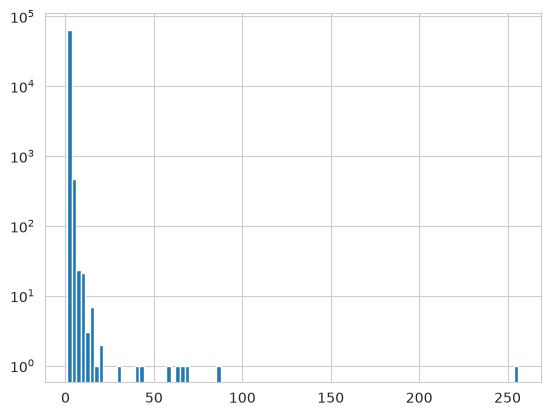

In [19]:
plt.hist(signatures_per_kb["n_mutations"], bins=100)
plt.yscale('log')

### Generalized additive model

In [20]:
genomic_features = pd.read_csv("data/landscapes/features/features_10kb.csv")

genomic_features.set_index("kb_id", inplace=True)
genomic_features.drop(columns=["mb_id"], inplace=True)
genomic_features

/tmp/ipykernel_63772/2772234633.py:3: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.set_index("kb_id", inplace=True)
/tmp/ipykernel_63772/2772234633.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.drop(columns=["mb_id"], inplace=True)


,A.C.G.T,cpg_fraction,replication_wave_signal
kb_id,,,
chr1:1,NaN,0.0000,NaN
chr1:10001,0.5923,0.0000,NaN
chr1:20001,0.5174,0.1075,48.091469
chr1:30001,0.4712,0.0000,48.124332
chr1:40001,0.3561,0.0000,48.220527
...,...,...,...
chr22:51260001,NaN,0.0000,46.454624
chr22:51270001,NaN,0.0000,45.836917
chr22:51280001,NaN,0.0000,NaN


#### Merge genomic features in one table

In [21]:
gene_expression = pd.read_csv("data/landscapes/features/expression_quartiles.csv").drop(["chr", "start", "end"], axis=1)
gene_expression

,expression_quartile,kb_id
0,intergenic,chr1:1
1,intergenic,chr1:10001
2,intergenic,chr1:20001
3,Q0,chr1:30001
4,intergenic,chr1:40001
...,...,...
309574,intergenic,chrY:59330001
309575,intergenic,chrY:59340001
309576,intergenic,chrY:59350001
309577,intergenic,chrY:59360001


In [22]:
genomic_features = genomic_features.join(gene_expression.set_index("kb_id"), how="left")

#### Merge genomic features with an effector variable

In [23]:
signatures_per_kb.reset_index(inplace=True)
genomic_features.reset_index(inplace=True)
genomic_features.rename(columns={"index": "kb_id"}, inplace=True)

genomic_features["kb_id"] = genomic_features["kb_id"].astype("string")
signatures_per_kb["kb_id"] = signatures_per_kb["kb_id"].astype("string")

/tmp/ipykernel_63772/4070735541.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  signatures_per_kb.reset_index(inplace=True)
/tmp/ipykernel_63772/4070735541.py:2: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.reset_index(inplace=True)
/tmp/ipykernel_63772/4070735541.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.rename(columns={"index": "kb_id"}, inplace=True)


In [24]:
genomic_features_with_signatures = genomic_features.merge(
    signatures_per_kb,
    on="kb_id",
    how="inner",
    validate="one_to_one",
).set_index("kb_id")

genomic_feature_columns = genomic_features.columns.drop("kb_id")
genomic_features_vs_sign = genomic_features_with_signatures[
    [*genomic_feature_columns, "SBS9", "SBS1", "SBS5","SBS19", "n_mutations"]
]

In [25]:
genomic_features_vs_sign

,A.C.G.T,cpg_fraction,replication_wave_signal,expression_quartile,SBS9,SBS1,SBS5,SBS19,n_mutations
kb_id,,,,,,,,,
chr1:830001,0.5093,0.0306,67.385025,intergenic,0,0,0,1,1
chr1:850001,0.6279,0.1238,70.357795,intergenic,0,0,0,1,1
chr1:870001,0.6734,0.4505,73.392487,Q0,0,0,0,0,1
chr1:940001,0.5431,0.0746,81.225182,Q4,0,0,0,0,1
chr1:1110001,0.6356,0.0577,80.045149,Q0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...
chr22:50910001,0.5991,0.1854,80.964899,Q3,0,0,0,1,1
chr22:51010001,0.5779,0.0767,80.608262,Q4,0,1,0,0,1
chr22:51080001,0.4468,0.0000,81.122783,intergenic,0,0,0,0,1


#### Filtering of the genomic regions

In [26]:
mask = ~genomic_features_vs_sign.index.str.split(":").str[0].isin({"chrX", "chrY"})
genomic_features_vs_sign = genomic_features_vs_sign[mask]

In [27]:
genomic_features_vs_sign.dropna(inplace=True)

/tmp/ipykernel_63772/465516023.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features_vs_sign.dropna(inplace=True)


hg19 genome
+ IgH locus coordinates – chr14:106,052,774-107,288,051 orientation -
+ IgL locus coordinates – chr22:22,380,474-23,265,085 orientation +
+ IgK locus coordinates – chr2:89,156,874-90,274,235 orientation +


In [28]:
region_ids = genomic_features_vs_sign.index.to_series().astype("string")
mask_igh = (
    region_ids.str.split(":").str[0] == "chr14"
) & region_ids.str.split(":").str[1].astype(int).between(
    106052774, 107288051
)
mask_igl = (
    region_ids.str.split(":").str[0] == "chr22"
) & region_ids.str.split(":").str[1].astype(int).between(
    22380474, 23265085
)
mask_igk = (
    region_ids.str.split(":").str[0] == "chr2"
) & region_ids.str.split(":").str[1].astype(int).between(
    89156874, 90274235
)

In [29]:
genomic_features_vs_sign = genomic_features_vs_sign.loc[~(mask_igh | mask_igl | mask_igk)]

In [30]:
genomic_features_vs_sign

,A.C.G.T,cpg_fraction,replication_wave_signal,expression_quartile,SBS9,SBS1,SBS5,SBS19,n_mutations
kb_id,,,,,,,,,
chr1:830001,0.5093,0.0306,67.385025,intergenic,0,0,0,1,1
chr1:850001,0.6279,0.1238,70.357795,intergenic,0,0,0,1,1
chr1:870001,0.6734,0.4505,73.392487,Q0,0,0,0,0,1
chr1:940001,0.5431,0.0746,81.225182,Q4,0,0,0,0,1
chr1:1110001,0.6356,0.0577,80.045149,Q0,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...
chr22:50910001,0.5991,0.1854,80.964899,Q3,0,0,0,1,1
chr22:51010001,0.5779,0.0767,80.608262,Q4,0,1,0,0,1
chr22:51080001,0.4468,0.0000,81.122783,intergenic,0,0,0,0,1


#### Training of the model

In [32]:
model_data = genomic_features_vs_sign.dropna().copy()
model_data["expression_quartile"] = pd.Categorical(
    model_data["expression_quartile"], categories=["Q0", "Q1", "Q2", "Q3", "Q4", "intergenic"]
    ).codes
X, y = model_data.iloc[:, :-5].to_numpy(dtype=float), model_data.iloc[:, -5].to_numpy(dtype=float)

In [33]:
y[0:20]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0.])

In [34]:
terms = s(0, n_splines=20) + s(1, n_splines=20) + s(2, n_splines=20) + f(3)

In [35]:
full_gam = LogisticGAM(terms=terms)
full_gam.fit(X, y)
full_gam.summary()

LogisticGAM                                                                                               
=============================================== ==========================================================
Distribution:                      BinomialDist Effective DoF:                                     38.5788
Link Function:                        LogitLink Log Likelihood:                                -27385.1099
Number of Samples:                        62122 AIC:                                            54847.3773
                                                AICc:                                           54847.4291
                                                UBRE:                                               2.8834
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                   0.2172
Feature Function                  Lam

/tmp/ipykernel_63772/3236201889.py:3: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  full_gam.summary()


In [36]:
full_gam.statistics_["pseudo_r2"]["explained_deviance"] * 100

np.float64(21.724335857878387)

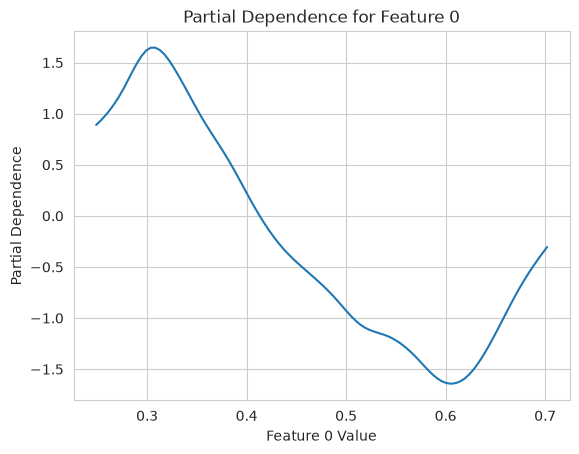

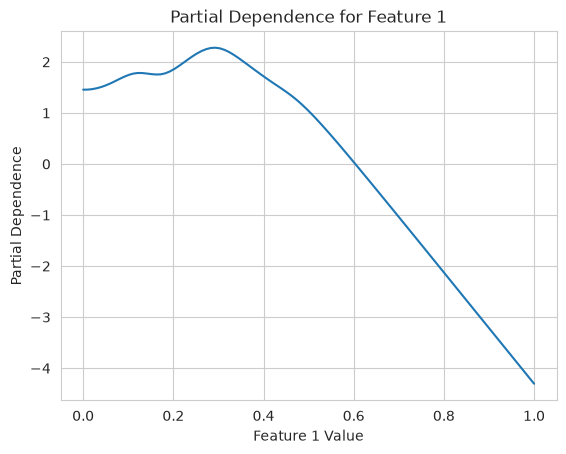

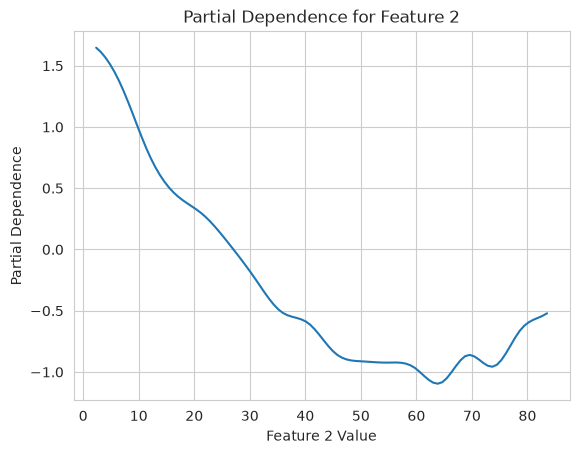

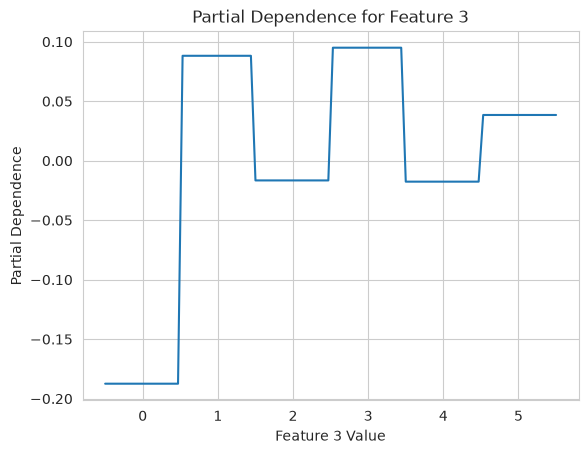

In [37]:
for i in range(X.shape[1]):
    XX = full_gam.generate_X_grid(term=i)
    plt.figure()
    plt.title(f"Partial Dependence for Feature {i}")
    plt.plot(XX[:, i], full_gam.partial_dependence(term=i, X=XX))
    plt.xlabel(f"Feature {i} Value")
    plt.ylabel("Partial Dependence")
    plt.show()

In [38]:
full_deviance = full_gam.statistics_["pseudo_r2"]["explained_deviance"]

In [39]:
full_deviance

np.float64(0.21724335857878385)

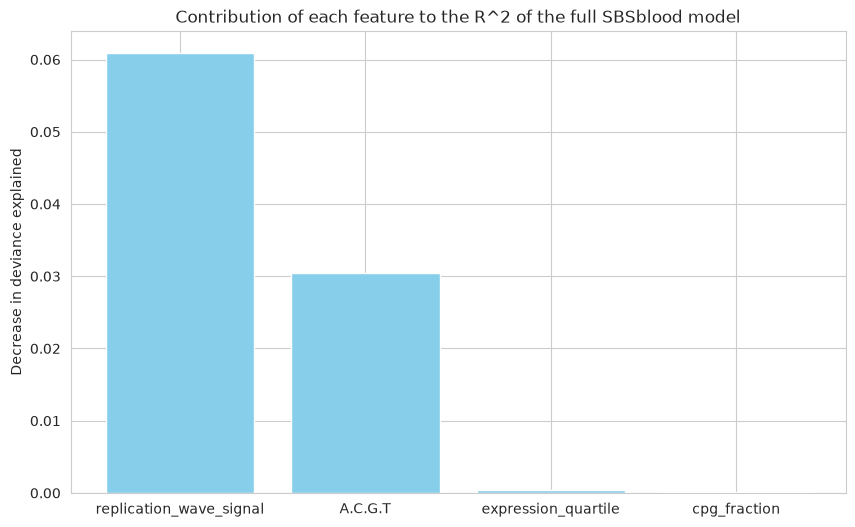

In [40]:
feature_names = genomic_features_vs_sign.columns[:-3].to_list()
feature_contributions = []

for feature in range(X.shape[1]):
    remaining = [i for i in range(X.shape[1]) if i != feature]
    X_reduced = X[:, remaining]
    terms = s(0, n_splines=20)

    for j in range(1, len(remaining)):
        terms += s(j, n_splines=20)

    reduced_gam = LogisticGAM(terms).fit(X_reduced, y)
    reduced_deviance = reduced_gam.statistics_["pseudo_r2"]["explained_deviance"]

    contribution = full_deviance - reduced_deviance
    feature_contributions.append(contribution)

feature_names, feature_contributions = zip(
    *sorted(zip(feature_names, feature_contributions), 
            key=lambda pair: pair[1], 
            reverse=True))

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(feature_names, feature_contributions, color='skyblue')
plt.ylabel("Decrease in deviance explained")
plt.title("Contribution of each feature to the R^2 of the full SBSblood model")
plt.show()

### Visualize expression agains different signatures

In [41]:
sign_vs_expression = genomic_features_vs_sign.groupby("expression_quartile").mean()

In [42]:
sign_vs_expression = sign_vs_expression.drop(columns=["n_mutations", "A.C.G.T", "cpg_fraction", "replication_wave_signal"])

In [39]:
sign_vs_expression

,SBS9,SBS1,SBSblood
expression_quartile,,,
Q0,969,282,1317
Q1,1214,295,1422
Q2,2360,711,3667
Q3,979,501,2905
Q4,662,342,2274
intergenic,14658,2240,12001


<Axes: xlabel='expression_quartile', ylabel='proportion'>

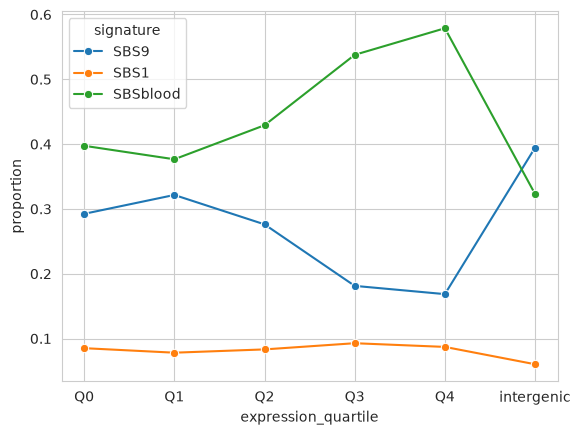

In [43]:
plot_data = sign_vs_expression.reset_index().melt(
    id_vars="expression_quartile",
    var_name="signature",
    value_name="proportion",
)
sns.lineplot(
    data=plot_data,
    x="expression_quartile",
    y="proportion",
    hue="signature",
    marker="o",
)

### Another Experiments

In [2]:
import pandas as pd

In [5]:
vcf_b = pd.read_csv("data/landscapes/som2_indel_SNV_allDF_v2.vcf", sep="\t", index_col=0)

In [6]:
vcf_b

,chr,pos,ref,mut,HQ.alt.freq,sample,donor
ID,,,,,,,
1:7075145_C/G,1,7075145.0,C,G,0.285714,PD40521di,KX001
1:10630501_T/A,1,10630501.0,T,A,0.666667,PD40521di,KX001
1:11192092_A/T,1,11192092.0,A,T,0.600000,PD40521di,KX001
1:17033082_C/G,1,17033082.0,C,G,0.297872,PD40521di,KX001
1:24523890_A/G,1,24523890.0,A,G,0.450000,PD40521di,KX001
...,...,...,...,...,...,...,...
X:33728918_A/AT,X,33728918.0,A,AT,1.000000,9_H12,AX001
X:84861842_TCTTA/T,X,84861842.0,TCTTA,T,0.928571,9_H12,AX001
X:89993242_CA/C,X,89993242.0,CA,C,0.928571,9_H12,AX001


In [26]:
vcf_b[
    vcf_b["ref"].str.len().eq(1)
    & vcf_b["mut"].str.len().eq(1)
]

,chr,pos,ref,mut,HQ.alt.freq,sample,donor
ID,,,,,,,
1:7075145_C/G,1,7075145.0,C,G,0.285714,PD40521di,KX001
1:10630501_T/A,1,10630501.0,T,A,0.666667,PD40521di,KX001
1:11192092_A/T,1,11192092.0,A,T,0.600000,PD40521di,KX001
1:17033082_C/G,1,17033082.0,C,G,0.297872,PD40521di,KX001
1:24523890_A/G,1,24523890.0,A,G,0.450000,PD40521di,KX001
...,...,...,...,...,...,...,...
Y:6721840_C/T,Y,6721840.0,C,T,1.000000,9_H12,AX001
Y:17565485_A/G,Y,17565485.0,A,G,1.000000,9_H12,AX001
Y:17852563_A/T,Y,17852563.0,A,T,1.000000,9_H12,AX001
